# Resultados: clasificación de nubes de puntos con PointNet y DGCNN

Este cuaderno lee los resultados de los **18 entrenamientos** (2 modelos × 3 experimentos × 3 semillas, 100 épocas cada uno) guardados en la carpeta `results`, recalcula las tablas del informe y comprueba que coincidan con lo escrito en él.

- **E1:** entrenar y evaluar en ModelNet40 (40 clases).
- **E2:** entrenar y evaluar en ScanObjectNN PB_T50_RS (15 clases).
- **E3:** entrenar en ModelNet40 (10 clases compartidas) y evaluar en ScanObjectNN.

No hace falta GPU para correr este cuaderno: solo lee archivos. Los entrenamientos se hicieron con `run_local.py` y `train.py` (ver el `README.md`). Los valores son media ± desviación estándar entre las 3 semillas (con `ddof = 1`, igual que `aggregate.py`).

In [1]:
import glob, json, os, re
import numpy as np
import pandas as pd
from IPython.display import Image, display

RES, FIGS = "results", "figs"
NM = {"pointnet": "PointNet", "dgcnn": "DGCNN"}

runs = {}   # (tarea, modelo) -> {semilla: resultado}
for f in sorted(glob.glob(f"{RES}/*_s[0-9]*.json")):
    m = re.match(r"(mn40|sonn|mn2sonn)_(pointnet|dgcnn)_s(\d+)\.json$", os.path.basename(f))
    if m:
        runs.setdefault((m[1], m[2]), {})[int(m[3])] = json.load(open(f))

total = sum(len(v) for v in runs.values())
print("Corridas encontradas:", total, "(esperado: 18)")
for (t, m), d in sorted(runs.items()):
    r0 = next(iter(d.values()))
    print(f"  {t:8s} {NM[m]:9s} semillas {sorted(d)}  épocas {r0['args']['epochs']}  AMP {r0['amp']}  "
          f"train {r0['n_train']}  test {r0['n_test']}")
assert total == 18

Corridas encontradas: 18 (esperado: 18)
  mn2sonn  DGCNN     semillas [1, 2, 3]  épocas 100  AMP True  train 4294  test 826
  mn2sonn  PointNet  semillas [1, 2, 3]  épocas 100  AMP False  train 4294  test 826
  mn40     DGCNN     semillas [1, 2, 3]  épocas 100  AMP True  train 9843  test 2468
  mn40     PointNet  semillas [1, 2, 3]  épocas 100  AMP False  train 9843  test 2468
  sonn     DGCNN     semillas [1, 2, 3]  épocas 100  AMP True  train 11416  test 2882
  sonn     PointNet  semillas [1, 2, 3]  épocas 100  AMP False  train 11416  test 2882


## Tablas de resultados

In [2]:
def ms(v):
    v = np.array(v, float)
    return v.mean(), v.std(ddof=1)

def pc(v, d=1):                       # porcentaje con coma decimal: "89,6 ± 0,6"
    mu, sd = ms(np.array(v) * 100)
    return f"{mu:.{d}f} ± {sd:.{d}f}".replace(".", ",")

def num(x, d=2):
    return f"{x:.{d}f}".replace(".", ",")

def principal(t, r):                  # E3 se reporta sobre ScanObjectNN
    return r["real"] if t == "mn2sonn" else r["test"]

tablas = {}
for t, titulo in (("mn40", "E1: ModelNet40"), ("sonn", "E2: ScanObjectNN")):
    filas = []
    for m in ("pointnet", "dgcnn"):
        rs = list(runs[(t, m)].values())
        filas.append({"Modelo": NM[m],
                      "OA (%)": pc([r["test"]["oa"] for r in rs]),
                      "mAcc (%)": pc([r["test"]["macc"] for r in rs]),
                      "F1 macro (%)": pc([r["test"]["f1_macro"] for r in rs]),
                      "Parámetros (M)": num(rs[0]["params_M"]),
                      "ms/muestra": num(np.mean([r["ms_per_sample"] for r in rs]))})
    tablas[t] = pd.DataFrame(filas)
    print(titulo, f"(entrenamiento {rs[0]['n_train']}, prueba {rs[0]['n_test']})")
    display(tablas[t])

filas = []
for m in ("pointnet", "dgcnn"):
    rs = list(runs[("mn2sonn", m)].values())
    filas.append({"Modelo": NM[m],
                  "OA ModelNet40 (%)": pc([r["test"]["oa"] for r in rs]),
                  "OA ScanObjectNN (%)": pc([r["real"]["oa"] for r in rs]),
                  "mAcc ScanObjectNN (%)": pc([r["real"]["macc"] for r in rs]),
                  "Brecha (pp)": pc([r["test"]["oa"] - r["real"]["oa"] for r in rs])})
tablas["mn2sonn"] = pd.DataFrame(filas)
print("E3: entrenar en ModelNet40 (10 clases), evaluar en ModelNet40 y ScanObjectNN",
      f"(entrenamiento {rs[0]['n_train']}, prueba {rs[0]['n_test']} en ModelNet40 y {rs[0]['real']['n']} en ScanObjectNN)")
display(tablas["mn2sonn"])

E1: ModelNet40 (entrenamiento 9843, prueba 2468)


,Modelo,OA (%),mAcc (%),F1 macro (%),Parámetros (M),ms/muestra
0,PointNet,"89,6 ± 0,6","85,0 ± 0,9","84,8 ± 0,7","3,47","0,52"
1,DGCNN,"91,3 ± 0,4","88,4 ± 0,4","88,3 ± 0,3","1,81","5,35"


E2: ScanObjectNN (entrenamiento 11416, prueba 2882)


,Modelo,OA (%),mAcc (%),F1 macro (%),Parámetros (M),ms/muestra
0,PointNet,"59,0 ± 0,9","52,8 ± 1,1","52,8 ± 1,2","3,47","0,53"
1,DGCNN,"74,6 ± 0,7","70,4 ± 0,7","71,4 ± 0,7","1,80","5,34"


E3: entrenar en ModelNet40 (10 clases), evaluar en ModelNet40 y ScanObjectNN (entrenamiento 4294, prueba 826 en ModelNet40 y 1990 en ScanObjectNN)


,Modelo,OA ModelNet40 (%),OA ScanObjectNN (%),mAcc ScanObjectNN (%),Brecha (pp)
0,PointNet,"96,4 ± 0,6","33,2 ± 0,4","30,5 ± 0,1","63,2 ± 0,2"
1,DGCNN,"96,9 ± 0,4","36,0 ± 0,9","34,0 ± 0,5","60,8 ± 0,8"


## Comprobación contra el informe

Se comparan, celda por celda, las tablas recalculadas con los valores escritos en el informe (Tablas 6, 7 y 8). Si alguna cifra no coincidiera, la celda se detendría con un error.

In [3]:
REPORTE = {
    "mn40": [["PointNet", "89,6 ± 0,6", "85,0 ± 0,9", "84,8 ± 0,7", "3,47", "0,52"],
             ["DGCNN",    "91,3 ± 0,4", "88,4 ± 0,4", "88,3 ± 0,3", "1,81", "5,35"]],
    "sonn": [["PointNet", "59,0 ± 0,9", "52,8 ± 1,1", "52,8 ± 1,2", "3,47", "0,53"],
             ["DGCNN",    "74,6 ± 0,7", "70,4 ± 0,7", "71,4 ± 0,7", "1,80", "5,34"]],
    "mn2sonn": [["PointNet", "96,4 ± 0,6", "33,2 ± 0,4", "30,5 ± 0,1", "63,2 ± 0,2"],
                ["DGCNN",    "96,9 ± 0,4", "36,0 ± 0,9", "34,0 ± 0,5", "60,8 ± 0,8"]],
}
todo_ok = True
for t, esperado in REPORTE.items():
    obtenido = tablas[t].values.tolist()
    for fila_o, fila_e in zip(obtenido, esperado):
        for col, (o, e) in enumerate(zip(fila_o, fila_e)):
            if o != e:
                todo_ok = False
                print(f"DIFERENCIA en {t}, {fila_e[0]}, columna {tablas[t].columns[col]}: cuaderno {o} / informe {e}")
print("Todas las cifras coinciden con el informe." if todo_ok else "Hay diferencias, revisar arriba.")
assert todo_ok

Todas las cifras coinciden con el informe.


In [4]:
# El modelo evaluado es el de la última época (no se elige la mejor sobre prueba):
# la exactitud de la última época del historial debe ser igual a la exactitud final guardada.
for (t, m), d in sorted(runs.items()):
    for s, r in sorted(d.items()):
        assert len(r["history"]) == 100, (t, m, s)
        assert abs(r["history"][-1]["test_oa"] - r["test"]["oa"]) < 1e-9, (t, m, s)
print("OK: las 18 corridas tienen 100 épocas y se reporta el modelo de la última época.")

OK: las 18 corridas tienen 100 épocas y se reporta el modelo de la última época.


## Cada semilla por separado

In [5]:
filas = []
for (t, m), d in sorted(runs.items()):
    for s, r in sorted(d.items()):
        x = principal(t, r)
        filas.append({"Experimento": t, "Modelo": NM[m], "Semilla": s, "OA (%)": round(100 * x["oa"], 2),
                      "mAcc (%)": round(100 * x["macc"], 2), "F1 macro (%)": round(100 * x["f1_macro"], 2),
                      "Entrenamiento (min)": round(r["train_time_s"] / 60, 1)})
display(pd.DataFrame(filas))

,Experimento,Modelo,Semilla,OA (%),mAcc (%),F1 macro (%),Entrenamiento (min)
0,mn2sonn,DGCNN,1,36.73,34.33,32.98,69.0
1,mn2sonn,DGCNN,2,36.38,34.36,33.16,68.6
2,mn2sonn,DGCNN,3,35.03,33.41,32.40,70.0
3,mn2sonn,PointNet,1,32.76,30.40,28.43,13.2
4,mn2sonn,PointNet,2,33.37,30.46,29.86,13.7
5,mn2sonn,PointNet,3,33.52,30.55,29.14,13.6
6,mn40,DGCNN,1,90.88,87.90,87.93,162.7
7,mn40,DGCNN,2,91.65,88.51,88.52,163.0
8,mn40,DGCNN,3,91.45,88.68,88.36,163.0
9,mn40,PointNet,1,89.71,84.92,84.90,30.8


## Figuras

Las figuras se generaron con `aggregate.py` a partir de los mismos archivos. Curvas de exactitud en prueba por época (media de 3 semillas con banda de ± 1 desviación estándar):

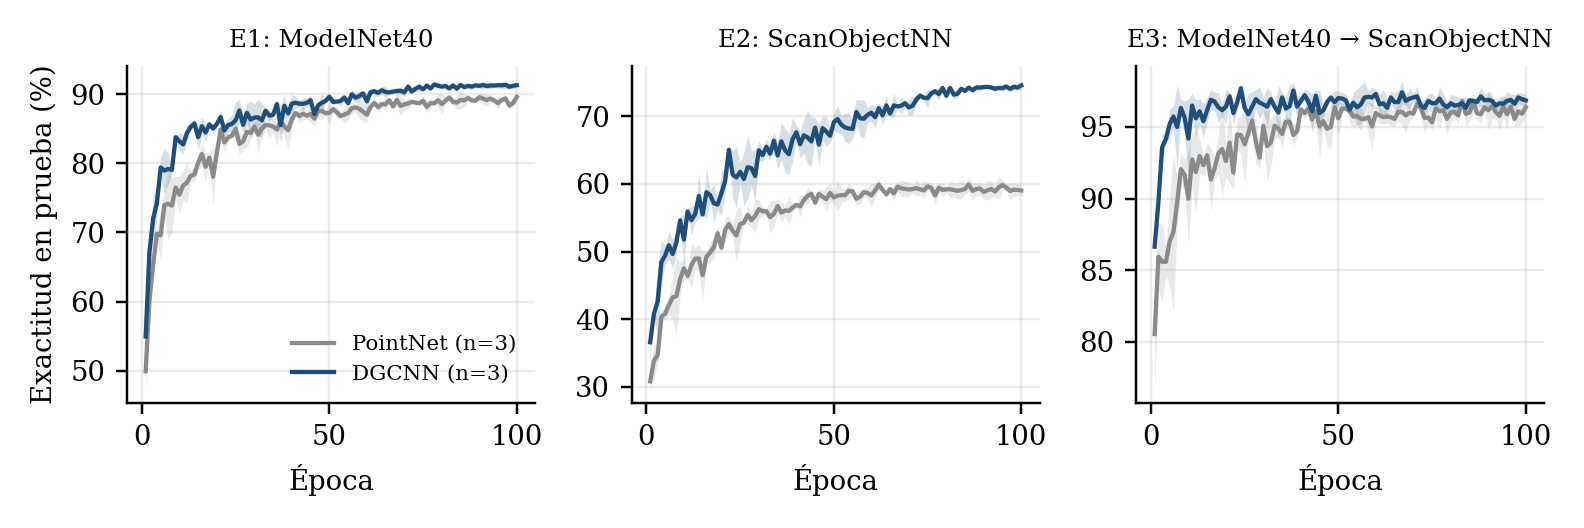

In [6]:
display(Image(filename=f"{FIGS}/curvas.png", width=900))

### Matrices de confusión (normalizadas por fila, suma de las 3 semillas)

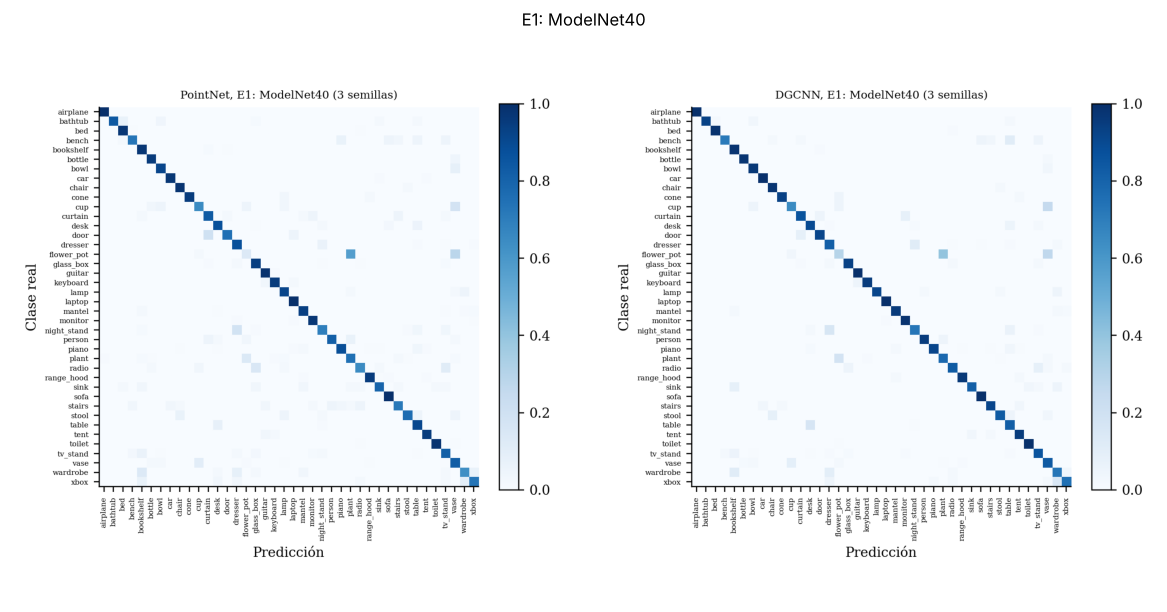

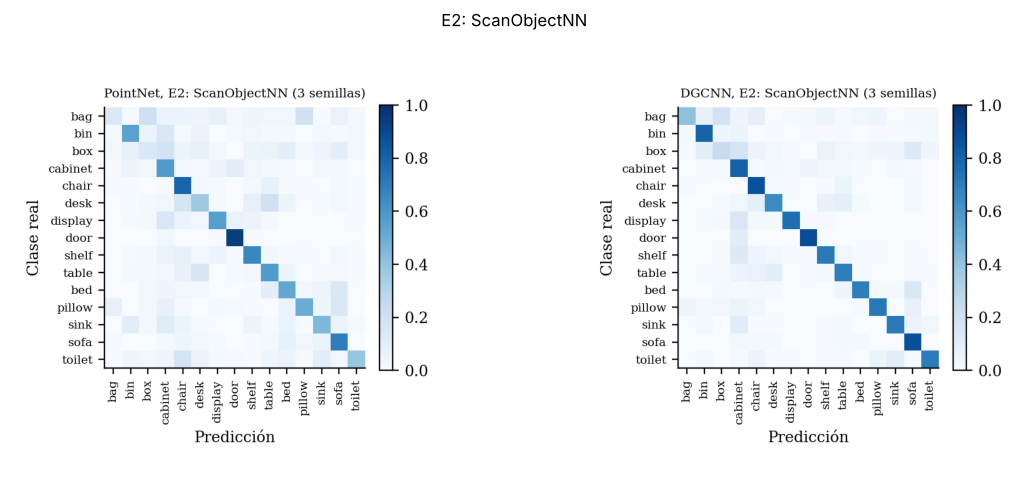

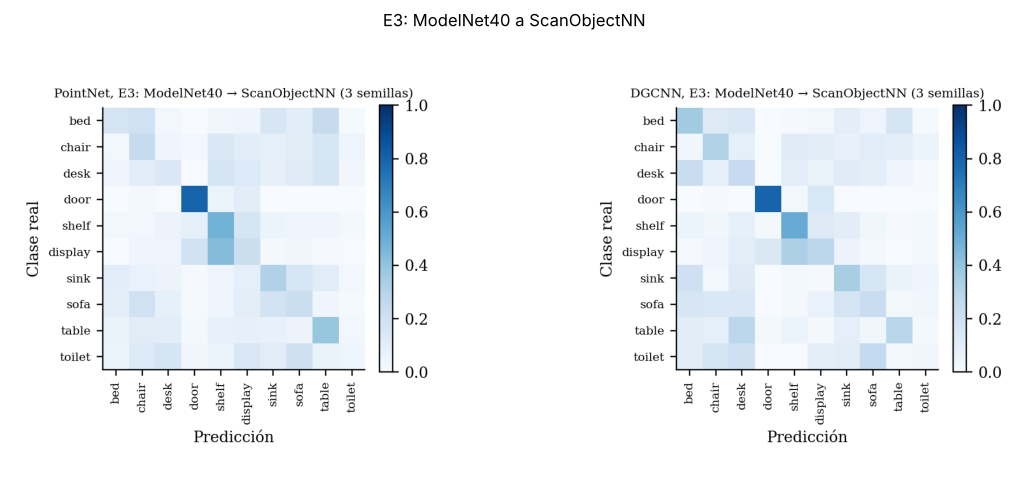

In [7]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
for t, titulo in (("mn40", "E1: ModelNet40"), ("sonn", "E2: ScanObjectNN"), ("mn2sonn", "E3: ModelNet40 a ScanObjectNN")):
    fig, ax = plt.subplots(1, 2, figsize=(12, 6.2 if t == "mn40" else 5))
    for a, m in zip(ax, ("pointnet", "dgcnn")):
        a.imshow(mpimg.imread(f"{FIGS}/confusion_{t}_{m}.png")); a.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

### Exactitud por clase en E3 (10 clases compartidas)

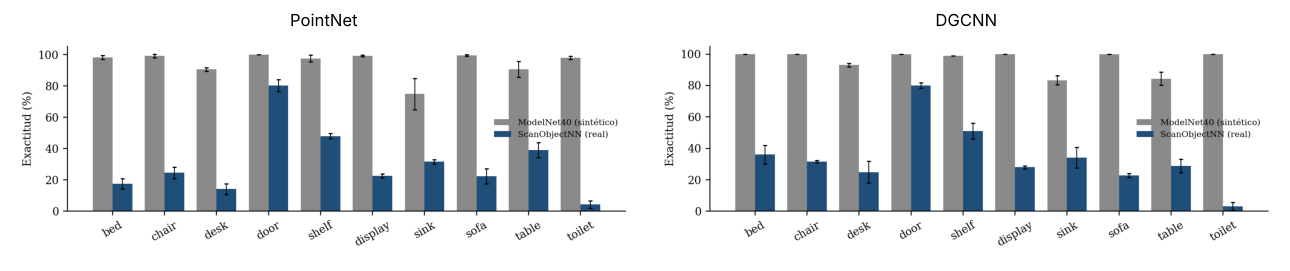

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, m in zip(ax, ("pointnet", "dgcnn")):
    a.imshow(mpimg.imread(f"{FIGS}/clases_e3_{m}.png")); a.axis("off"); a.set_title(NM[m])
plt.tight_layout(); plt.show()

### Ejemplos de predicciones (azul: acierto, rojo: error)

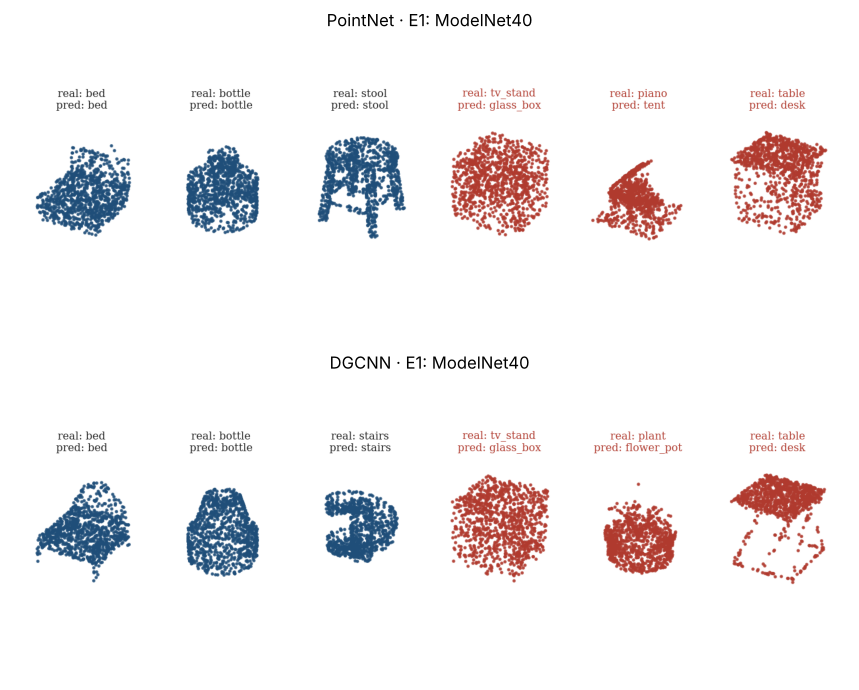

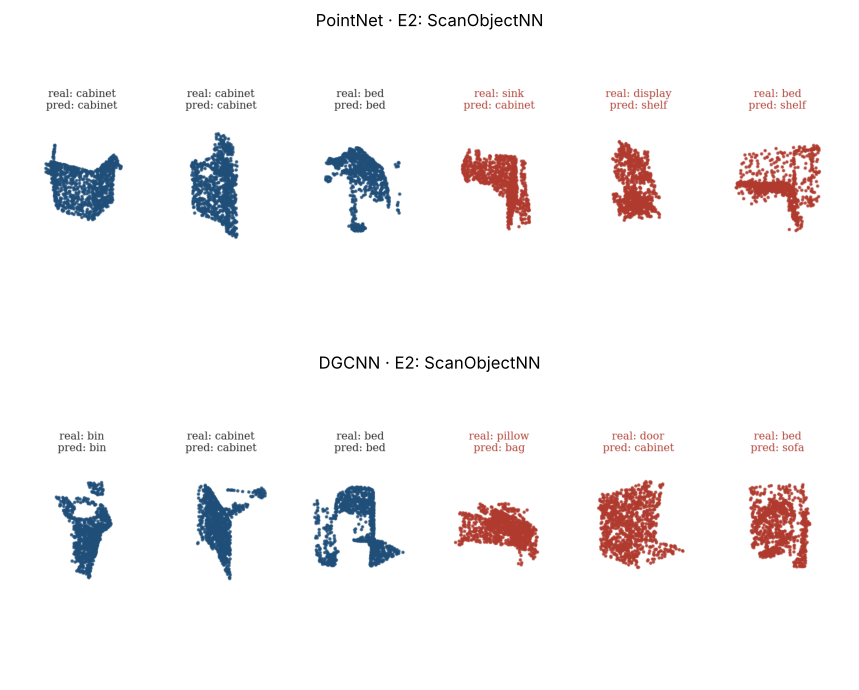

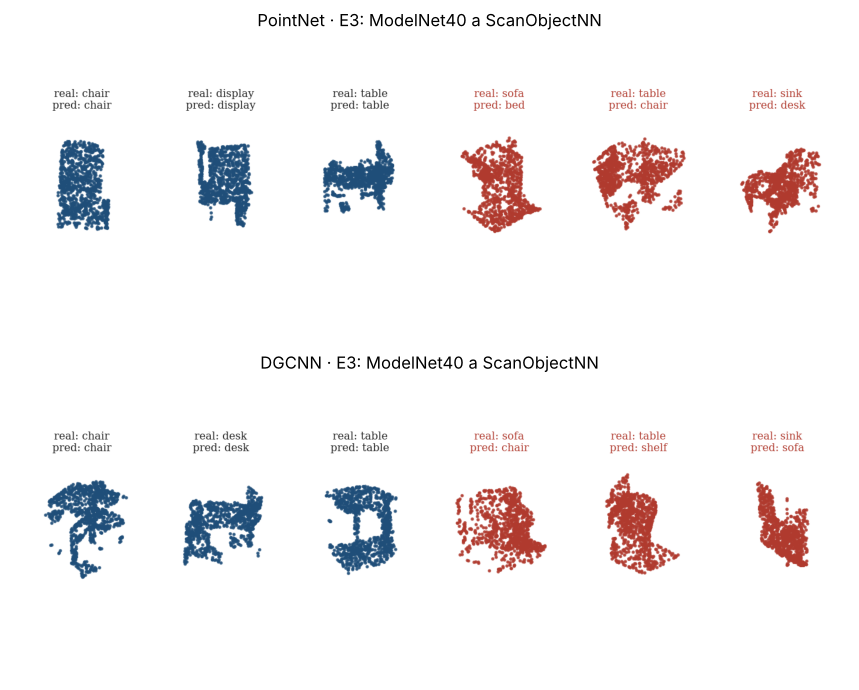

In [9]:
for t, titulo in (("mn40", "E1: ModelNet40"), ("sonn", "E2: ScanObjectNN"), ("mn2sonn", "E3: ModelNet40 a ScanObjectNN")):
    fig, ax = plt.subplots(2, 1, figsize=(13, 7))
    for a, m in zip(ax, ("pointnet", "dgcnn")):
        a.imshow(mpimg.imread(f"{FIGS}/ejemplos_{t}_{m}.png")); a.axis("off"); a.set_title(f"{NM[m]} · {titulo}")
    plt.tight_layout(); plt.show()